# 📘 1. Base de datos

Este capítulo presenta el problema, de dónde vienen los datos, qué contiene cada variable, cómo está estructurada la base, su tamaño real, su calidad y las consideraciones éticas. Los números salen del panel limpio que se construye en el [capítulo 2](02_carga_y_limpieza.ipynb).

## 🎯 1.1 Problema y justificación

**Problema.** Pronosticar la **venta diaria total** de cada negocio a partir de su propia historia reciente, incluida la venta por medio de pago de los días anteriores. El horizonte propuesto es el **día siguiente** y se fija en el capítulo 3.

**Contexto.** Los negocios son estaciones de servicio (EDS), tiendas de conveniencia y KCOs (kioscos: máquinas de autoservicio de snacks y bebidas) operados por **Masser**, operadora de la marca Terpel. La venta se registra por medio de pago (efectivo, datáfono, créditos corporativos como Rumbo o Mi Empresa, etc.) en varios sistemas de punto de venta.

**Justificación.**

| Por qué importa | Detalle |
|---|---|
| Uso operativo | Un pronóstico diario por negocio sirve para planear personal, inventario y metas comerciales, y para detectar días anómalos (una venta muy distinta de lo esperado). |
| Interés como problema de ML | Son cientos de series cortas y muy heterogéneas (la venta media por negocio varía en varios órdenes de magnitud), con patrón semanal. Obliga a cuidar la validación temporal y la fuga de datos. |
| Tipo de tarea | **Regresión** sobre un **panel temporal**: una observación por negocio y día. |

Todos los medios de pago cuentan como venta, incluidos los de crédito. El objetivo es la venta, no el momento en que el dinero entra a caja.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
np.random.seed(SEED)

DATA = Path("../../Data")

# paleta del libro (la misma en todos los capítulos)
PALETA = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
AZUL, NARANJA = PALETA[0], PALETA[1]
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10,
    "axes.prop_cycle": plt.cycler(color=PALETA),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
    "axes.edgecolor": "#8a8983", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.titleweight": "bold", "axes.titlesize": 12,
})
pd.set_option("display.float_format", "{:,.2f}".format)

panel = pd.read_csv(DATA / "processed" / "panel_negocio_dia.csv", parse_dates=["fecha"])
print(f"panel: {panel.shape[0]:,} filas x {panel.shape[1]} columnas")

panel: 37,828 filas x 14 columnas


## 🏢 1.2 Fuente, licencia y disponibilidad

| Aspecto | Detalle |
|---|---|
| Fuente | Datos internos de **Masser** (operadora de Terpel): recibos de venta de los sistemas de punto de venta TPos, Sckuba, Satélite (GNV, Canastilla, LIQ) y registros manuales, ya agregados por negocio, día y medio de pago. Incluye el catálogo de medios de pago (`vw_PaymetMethods`). |
| Periodo | 1 de julio al 24 de septiembre de 2026 (se usa hasta el 23; ver [2.4](02_carga_y_limpieza.ipynb)) |
| Licencia / permiso | Uso **autorizado por la empresa** con fines académicos e investigativos, y con posible uso empresarial posterior. |
| Disponibilidad | La base **no es pública** y el repositorio no contiene datos. Está en una carpeta privada de OneDrive. El profesor puede **solicitar acceso** al autor, y el acceso se concede tras tramitar la autorización con la empresa. |
| Reproducibilidad | El código completo está en los notebooks y las semillas están fijas (`SEED = 42`). Con acceso autorizado a los datos, el libro se reproduce ejecutando los capítulos en orden. |

```{warning}
Como la base no es pública, un lector sin acceso autorizado no puede re-ejecutar los notebooks. Por eso el libro se publica **con las salidas guardadas** y documenta cada paso de limpieza en el capítulo 2.
```

## 📖 1.3 Diccionario de variables

### Datos crudos (una fila por fuente × negocio × día × medio de pago)

| Variable | Tipo | Descripción |
|---|---|---|
| `Source` | categórica (6 niveles) | Sistema de origen: TPos Recibos, Sckuba, Satélite Ventas GNV / Canastilla / LIQ, Manual |
| `Biz.ID` | identificador | Código interno del negocio (se anonimiza como `N###`) |
| `Date` | fecha | Día de la venta (sin hora) |
| `PM.ID` | categórica (19 usados de 26) | Medio de pago; su nombre y categoría salen del catálogo |
| `Recibo.Total` | texto → numérica (COP) | Valor vendido en ese día y medio de pago. Formato `$ 1234,56`, con coma decimal |

### Panel limpio (una fila por negocio × día)

In [2]:
# [IA] diccionario del panel: tipo, rol y descripción de cada columna
dicc = pd.DataFrame([
    ("negocio", "identificador", "Negocio anonimizado (N001…N453)", "Agrupa la serie; no es predictor"),
    ("fecha", "fecha", "Día de la venta", "Índice temporal; de aquí salen variables de calendario"),
    ("pm_efectivo", "numérica (COP)", "Venta en efectivo", "Predictor solo como rezago"),
    ("pm_datafono", "numérica (COP)", "Venta con datáfono (tarjetas)", "Predictor solo como rezago"),
    ("pm_rumbo", "numérica (COP)", "Venta con crédito corporativo Rumbo", "Predictor solo como rezago"),
    ("pm_mi_empresa", "numérica (COP)", "Venta con crédito corporativo Mi Empresa", "Predictor solo como rezago"),
    ("pm_credito_clientes", "numérica (COP)", "Venta a crédito propio del negocio", "Predictor solo como rezago"),
    ("pm_otros", "numérica (COP)", "Suma de los 14 medios que pesan < 1 %", "Predictor solo como rezago"),
    ("cat_contado", "numérica (COP)", "Venta de contado (según el catálogo)", "Solo descriptiva"),
    ("cat_credito_propio", "numérica (COP)", "Venta a crédito propio", "Solo descriptiva"),
    ("cat_credito_empresa", "numérica (COP)", "Venta con créditos corporativos", "Solo descriptiva"),
    ("venta_total", "numérica (COP)", "Suma de todos los medios y fuentes del día", "**Variable objetivo**"),
    ("n_fuentes", "entera", "Número de sistemas que reportaron ese día", "Control / posible predictor"),
    ("sin_registro", "binaria", "1 si el día no tenía filas (venta 0 por regla del negocio)", "Control / posible predictor"),
], columns=["variable", "tipo", "descripción", "rol"])

# verifico que el diccionario cubra exactamente las columnas del panel
print("columnas sin documentar:", set(panel.columns) - set(dicc["variable"]))
dicc.set_index("variable")

columnas sin documentar: set()


,tipo,descripción,rol
variable,,,
negocio,identificador,Negocio anonimizado (N001…N453),Agrupa la serie; no es predictor
fecha,fecha,Día de la venta,Índice temporal; de aquí salen variables de ca...
pm_efectivo,numérica (COP),Venta en efectivo,Predictor solo como rezago
pm_datafono,numérica (COP),Venta con datáfono (tarjetas),Predictor solo como rezago
pm_rumbo,numérica (COP),Venta con crédito corporativo Rumbo,Predictor solo como rezago
pm_mi_empresa,numérica (COP),Venta con crédito corporativo Mi Empresa,Predictor solo como rezago
pm_credito_clientes,numérica (COP),Venta a crédito propio del negocio,Predictor solo como rezago
pm_otros,numérica (COP),Suma de los 14 medios que pesan < 1 %,Predictor solo como rezago
cat_contado,numérica (COP),Venta de contado (según el catálogo),Solo descriptiva


### Interpretación

La variable objetivo es `venta_total`. La venta por medio de pago del **mismo día** suma exactamente el objetivo, así que usarla como predictor sería **fuga de datos directa**: por eso los medios solo pueden entrar como rezagos (días anteriores). Las columnas `cat_*` son otra forma de sumar los mismos montos y se dejan solo para describir los datos.

## 🧱 1.4 Estructura

| Aspecto | Valor |
|---|---|
| Unidad de observación | **negocio × día** |
| Tipo | **Panel temporal desbalanceado**: muchas series diarias, una por negocio, y no todas cubren el periodo completo |
| Frecuencia | Diaria, sin huecos dentro del periodo activo de cada negocio (los días sin venta se completaron con 0, ver [2.8](02_carga_y_limpieza.ipynb)) |
| Periodo | 1 jul – 23 sep 2026 (85 días, 12 semanas + 1 día) |

In [3]:
dias_neg = panel.groupby("negocio")["fecha"].agg(inicio="min", fin="max", dias="size")
inicio, fin = panel["fecha"].min(), panel["fecha"].max()

tipo = np.select(
    [(dias_neg["inicio"] == inicio) & (dias_neg["fin"] == fin), dias_neg["inicio"] > inicio],
    ["periodo completo", "entra tarde (recibido de franquicia)"],
    default="sale antes (entregado en franquicia)")
estructura = pd.Series(tipo, index=dias_neg.index).value_counts().rename("negocios").to_frame()
estructura["días de historia (mediana)"] = [dias_neg.loc[tipo == t, "dias"].median() for t in estructura.index]
estructura

,negocios,días de historia (mediana)
periodo completo,431,85.00
entra tarde (recibido de franquicia),12,52.00
sale antes (entregado en franquicia),9,73.00


### Interpretación

Casi todos los negocios cubren los 85 días. Unos pocos entran o salen por cambios de franquicia, así que el panel es **desbalanceado**. Esto importa para la validación: una partición cronológica deja negocios que aparecen solo en test o que solo están en train, y así se tratarán en el capítulo 3.

## 📏 1.5 Tamaño y tamaño efectivo de muestra

El enunciado pide al menos 20 000 observaciones y que se reporten $n$, $p$ y el número de entidades independientes.

In [4]:
# [IA] p = columnas del panel que pueden ser predictores (sin id, fecha, objetivo ni las cat_* que son redundantes)
predictores_base = [c for c in panel if c.startswith("pm_")] + ["n_fuentes", "sin_registro"]
n = len(panel)
p = len(predictores_base) + 1  # +1 por el día de la semana que sale de la fecha
entidades = panel["negocio"].nunique()

tamano = pd.Series({
    "n (filas negocio-día)": f"{n:,}",
    "p (predictores base)": p,
    "n / p": f"{n / p:,.0f}",
    "entidades independientes (negocios)": entidades,
    "entidades / p": f"{entidades / p:.1f}",
    "días por negocio (mediana)": int(dias_neg["dias"].median()),
}).to_frame("valor")
tamano

,valor
n (filas negocio-día),"37,828"
p (predictores base),9
n / p,"4,203"
entidades independientes (negocios),452
entidades / p,50.2
días por negocio (mediana),85


### Interpretación

Con $n$ = 37 828 filas se cumple el mínimo de 20 000. Pero las filas **no son independientes**: los días de un mismo negocio están muy correlacionados entre sí (el negocio que vende mucho hoy vende mucho mañana).

```{note}
**Tamaño efectivo de muestra.** La unidad independiente es el **negocio (452)**, no la fila. Con 85 días por negocio hay mucha información sobre la dinámica de cada serie, pero poca sobre cómo varían los negocios entre sí. Por eso: (1) la validación debe respetar el tiempo (nada de *k-fold* aleatorio), y (2) las métricas y sus intervalos se interpretan con 452 entidades en mente, no con 37 mil.
```

El $p$ base es pequeño (6 medios + 2 controles + día de la semana). El $p$ final crece cuando se crean rezagos (cap. 7), pero seguirá muy por debajo de $n$.

## 🔍 1.6 Calidad de los datos

El detalle está en el capítulo 2. Este es el resumen:

| Aspecto | Hallazgo | Mecanismo / causa | Tratamiento |
|---|---|---|---|
| Nulos | 0 en los datos crudos | — | — |
| Días sin fila | 197 negocio-días dentro del periodo activo de 44 negocios | **Conocido**: el negocio no vendió (regla del negocio). No es faltante aleatorio: es un cero estructural | Venta 0 + marca `sin_registro` |
| Días antes o después del periodo activo | Negocios que entran o salen | Cambio de franquicia: la entidad no operaba | No se crean filas |
| Duplicados | 0 dentro de una fuente | Los repetidos entre fuentes son líneas de venta distintas | Se suman |
| Día incompleto | 24 sep con 369 de ~445 negocios | Exportación a mitad del día | Se excluye |
| Negocio inconsistente | 1 negocio con cambio de POS incoherente | Migración de sistema | Se excluye |
| Valores imposibles | Ninguno de formato. Montos negativos (reversos) y ceros (consumo propio) | Operación real | Se conservan |

### Valores atípicos (descriptivo)

Para no mirar el periodo de prueba, los atípicos se describen **solo con julio y agosto**. Para cada negocio comparo cada día con la mediana de ese negocio en escala log, con una regla robusta (distancia mayor a 3 MAD escaladas). **Aquí no se elimina nada**: el tratamiento se decide en el capítulo 7 con reglas ajustadas solo en train.

In [5]:
# [IA] atípicos por negocio con z robusta en log (solo jul-ago, solo para describir)
ja = panel[(panel["fecha"] < "2026-09-01") & (panel["venta_total"] > 0)].copy()
ja["log_v"] = np.log(ja["venta_total"])
g = ja.groupby("negocio")["log_v"]
mad = g.transform(lambda s: (s - s.median()).abs().median()) * 1.4826
ja["z_rob"] = (ja["log_v"] - g.transform("median")) / mad.replace(0, np.nan)

atip = ja["z_rob"].abs() > 3
print(f"negocio-días jul-ago con venta > 0: {len(ja):,}")
print(f"atípicos (|z robusta| > 3): {atip.sum():,} ({atip.mean():.1%}) en {ja.loc[atip, 'negocio'].nunique()} negocios")
print(f"  por debajo de lo normal: {(ja['z_rob'] < -3).sum():,} | por encima: {(ja['z_rob'] > 3).sum():,}")

no_pos = panel[(panel["fecha"] < "2026-09-01") & (panel["venta_total"] <= 0)]
print(f"negocio-días jul-ago con venta <= 0: {len(no_pos)} (de ellos sin registro: {no_pos['sin_registro'].sum()})")

negocio-días jul-ago con venta > 0: 27,428
atípicos (|z robusta| > 3): 1,231 (4.5%) en 297 negocios
  por debajo de lo normal: 1,059 | por encima: 172
negocio-días jul-ago con venta <= 0: 153 (de ellos sin registro: 152)


### Interpretación

Hay atípicos dentro de cada negocio, y la mayoría son días de venta **mucho más baja** de lo normal para ese negocio (cierres parciales, días con reversos, arranques de operación). No son errores de captura, así que no se eliminan: son días que el modelo también tendrá que enfrentar. Los días con venta ≤ 0 son casi todos días sin venta (ceros estructurales) y unos pocos reversos. Se tratan en el preprocesamiento porque `log1p` no admite valores negativos.

## ⚖️ 1.7 Sesgos y limitaciones

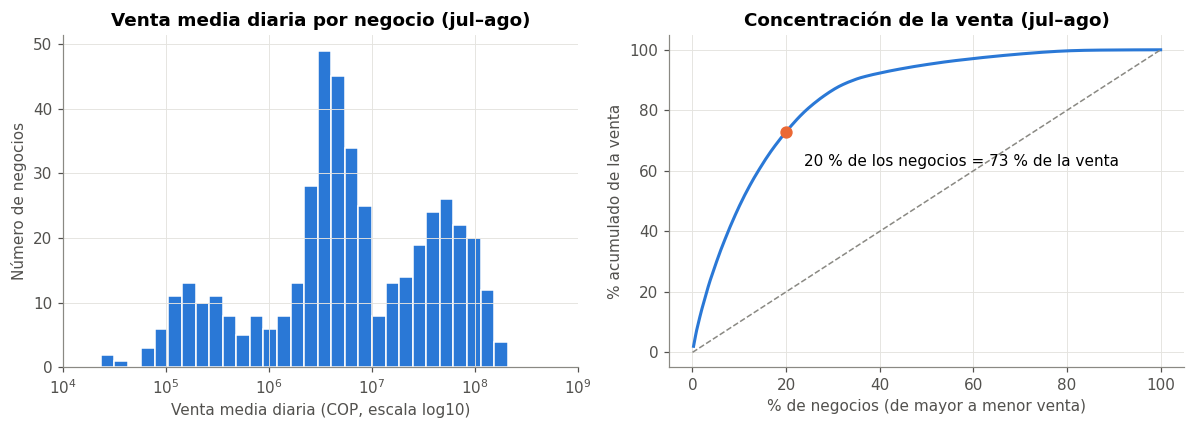

venta media diaria: mín 23,073 | mediana 5,369,626 | máx 207,077,120 COP
el negocio más grande vende 8,975 veces lo que el más pequeño
10 % más grande = 48 % de la venta


In [6]:
# [IA] concentración de la venta entre negocios (jul-ago, para no mirar test)
media_neg = panel[panel["fecha"] < "2026-09-01"].groupby("negocio")["venta_total"].mean().sort_values(ascending=False)
acum = media_neg.cumsum() / media_neg.sum() * 100
x = np.arange(1, len(acum) + 1) / len(acum) * 100

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ax = axes[0]
ax.hist(np.log10(media_neg[media_neg > 0]), bins=30, color=AZUL, edgecolor="white")
ax.set_title("Venta media diaria por negocio (jul–ago)")
ax.set_xlabel("Venta media diaria (COP, escala log10)")
ax.set_ylabel("Número de negocios")
ticks = range(4, 10)
ax.set_xticks(list(ticks))
ax.set_xticklabels([f"$10^{t}$" for t in ticks])

ax = axes[1]
ax.plot(x, acum.values, color=AZUL, lw=2)
ax.plot([0, 100], [0, 100], color="#8a8983", lw=1, ls="--")
top20 = acum.iloc[int(len(acum) * 0.2) - 1]
ax.scatter([20], [top20], color=NARANJA, s=50, zorder=3)
ax.annotate(f"20 % de los negocios = {top20:.0f} % de la venta", (20, top20), xytext=(12, -22), textcoords="offset points")
ax.set_title("Concentración de la venta (jul–ago)")
ax.set_xlabel("% de negocios (de mayor a menor venta)")
ax.set_ylabel("% acumulado de la venta")
plt.tight_layout()
plt.show()

print(f"venta media diaria: mín {media_neg.min():,.0f} | mediana {media_neg.median():,.0f} | máx {media_neg.max():,.0f} COP")
print(f"el negocio más grande vende {media_neg.max() / media_neg.min():,.0f} veces lo que el más pequeño")
print(f"10 % más grande = {acum.iloc[int(len(acum) * 0.1) - 1]:.0f} % de la venta")

### Interpretación

La venta media diaria va de unas decenas de miles a unos 200 millones de pesos: **casi 4 órdenes de magnitud**. El histograma en escala log muestra **tres grupos** (alrededor de $10^5$, $5\times10^6$ y $5\times10^7$ COP/día). Es probable que correspondan a los tipos de negocio (kiosco, tienda, EDS), pero la base no trae esa variable, así que es una **hipótesis sin verificar**. La venta está muy concentrada: el 20 % de los negocios hace cerca de tres cuartas partes de la venta. Esto tiene dos consecuencias: (1) en escala original el error de un modelo lo dominan los negocios grandes, lo que justifica trabajar en escala log y reportar métricas relativas como MAPE; (2) un modelo global tiene que servir a negocios muy distintos.

| Sesgo / limitación | Descripción | Consecuencia |
|---|---|---|
| **Historia corta** | Solo 85 días (≈ 12 semanas) | No se puede estudiar estacionalidad anual ni mensual con solidez, y casi nada la deriva a largo plazo |
| **Festivos** | En el periodo hay 3 festivos (lun 20 jul, vie 7 ago, lun 17 ago), todos en julio–agosto. Septiembre no tiene ninguno | Muy pocos casos para modelar el efecto festivo, y el test no contiene festivos |
| **Supervivencia / franquicias** | Negocios que entran o salen por franquicia | Los negocios nuevos tienen pocos rezagos; los que salen no aparecen en test |
| **Tipo de negocio no observado** | La base no dice si un negocio es EDS, tienda o kiosco (KCO) | La heterogeneidad entre tipos queda "escondida" en el nivel de cada negocio |
| **Heterogeneidad de escala** | Varios órdenes de magnitud entre negocios | Escala log y métricas relativas |
| **Sistemas de origen** | 6 fuentes con cambios de software posibles | Riesgo de quiebres artificiales en la serie (ya se excluyó un caso) |
| **Representatividad** | Solo negocios de una operadora, en un trimestre | Las conclusiones no se extienden a otras operadoras ni a otras épocas del año |

## 🔒 1.8 Consideraciones éticas y de privacidad

- **Sin datos personales.** La base está agregada por negocio, día y medio de pago. No contiene clientes, empleados, placas ni transacciones individuales.
- **Anonimización.** Los negocios se muestran como `N###`. La tabla de equivalencias se guarda fuera del repositorio y no se publica. Tampoco se muestran nombres, ubicaciones ni otros atributos que permitan identificar un punto de venta.
- **Confidencialidad comercial.** La empresa autorizó el uso académico e investigativo. Los datos no se publican: solo los resultados agregados de este libro, y el acceso a la base se da caso por caso con autorización de la empresa.
- **Uso responsable del modelo.** Un pronóstico no debe usarse por sí solo para evaluar o sancionar a la administración de un negocio: la venta depende de factores que el modelo no ve (obras en la vía, precios, clima, cambios de franquicia).
- **Transparencia.** Todas las decisiones de limpieza (exclusiones, ceros, reversos) quedan documentadas en el capítulo 2, con su justificación.

## ✅ Resumen del capítulo

| Aspecto | Resultado |
|---|---|
| Problema | Regresión: venta total del día siguiente por negocio |
| Fuente | Masser (operadora Terpel), uso académico autorizado, datos privados con acceso bajo solicitud |
| Unidad | negocio × día, panel desbalanceado |
| Periodo | 1 jul – 23 sep 2026 (85 días) |
| Tamaño | $n$ = 37 828, $p$ base = 9, **452 negocios** (tamaño efectivo) |
| Calidad | Sin nulos ni duplicados. Ceros estructurales y reversos documentados |
| Principal limitación | Solo ~3 meses de historia, sin festivos en septiembre |

```{tip}
Hallazgos que se usan más adelante: **(1)** usar la venta por medio del mismo día sería fuga, así que solo entra como rezago (cap. 5 y 7); **(2)** la escala es muy heterogénea, lo que lleva a escala log y MAPE (cap. 3 y 7); **(3)** las filas no son independientes, así que la validación es temporal (cap. 3 y 8).
```